# Sprints AI-Powered Learner Success & Support Agent
## Notebook 01: Practical Data Analytics, Relational Database & EDA (Sprint 1)
**Client:** Sprints (sprints.ai)  
**Track:** AI Pioneers Nationwide Cohort  
**Author:** Mohammed Wael (Lead AI Engineer)

---

### Notebook Overview
This notebook addresses **Sprint 1: Practical Data Analytics**, fulfilling all technical graduation requirements:
1. **Relational Database Verification**: Querying `database/sprints_learners.db` across all 6 normalized tables (2,000 learners, 9,101 quiz records, 2,000 support tickets).
2. **Analytical SQL Extraction**: Executing complex multi-table joins, window functions, and CTEs.
3. **Query 5 Join Multiplication Fix**: Using independent Common Table Expressions (CTEs) to eliminate Cartesian product anomalies in module-level aggregations.
4. **pandas Data Cleaning & Imputation**: Temporal forward-fill (`ffill`) and regional median imputation preserving time-series validity without target leakage.
5. **Matplotlib Visual Analytics**: Mapping dropout rates across Egyptian governorates, 5-week trajectory curves, and correlation heatmaps.

In [1]:
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print("Imported core analytics libraries successfully.")

Imported core analytics libraries successfully.


### 1. Relational Database Verification
We connect to `sprints_learners.db` and inspect table row counts across the 2,000 enrolled learners.

In [2]:
db_path = os.path.join('..', 'database', 'sprints_learners.db')
conn = sqlite3.connect(db_path)
cur = conn.cursor()

tables = ['cohorts', 'learners', 'course_modules', 'quiz_grades', 'support_tickets', 'interaction_logs']
counts = {}
for t in tables:
    cur.execute(f"SELECT COUNT(*) FROM {t}")
    counts[t] = cur.fetchone()[0]

df_counts = pd.DataFrame(list(counts.items()), columns=['Table Name', 'Record Count'])
df_counts

,Table Name,Record Count
0,cohorts,2
1,learners,2000
2,course_modules,5
3,quiz_grades,9101
4,support_tickets,2006
5,interaction_logs,2000


### 2. Analytical SQL Queries

#### Query 2: Early Risk Detection via Progressive Grade Degradation
Flags learners whose weekly quiz score dropped by $\ge 15$ points compared to their baseline Week 1 score.

In [3]:
q_degradation = '''
WITH week1_scores AS (
    SELECT learner_id, score AS w1_score
    FROM quiz_grades
    WHERE week_number = 1 AND score IS NOT NULL
),
subsequent_scores AS (
    SELECT learner_id, week_number, score AS current_score
    FROM quiz_grades
    WHERE week_number > 1 AND score IS NOT NULL
)
SELECT 
    l.learner_id,
    l.full_name,
    l.cohort_city,
    w1.w1_score,
    s.week_number AS degraded_at_week,
    s.current_score,
    ROUND(w1.w1_score - s.current_score, 1) AS score_drop
FROM learners l
JOIN week1_scores w1 ON l.learner_id = w1.learner_id
JOIN subsequent_scores s ON l.learner_id = s.learner_id
WHERE (w1.w1_score - s.current_score) >= 15.0
ORDER BY score_drop DESC
LIMIT 10;
'''
df_degrad = pd.read_sql_query(q_degradation, conn)
df_degrad

,learner_id,full_name,cohort_city,w1_score,degraded_at_week,current_score,score_drop
0,LRN-1288,Learner 1288,Cairo,69.4,5,5.0,64.4
1,LRN-1787,Learner 1787,Alexandria,68.4,5,5.2,63.2
2,LRN-2196,Learner 2196,Tanta,82.0,5,19.3,62.7
3,LRN-2783,Learner 2783,Giza,82.0,5,19.7,62.3
4,LRN-2443,Learner 2443,Cairo,67.6,5,6.9,60.7
5,LRN-1291,Learner 1291,Minya,82.0,5,21.5,60.5
6,LRN-1742,Learner 1742,Giza,64.9,5,5.1,59.8
7,LRN-2463,Learner 2463,Alexandria,67.6,5,7.8,59.8
8,LRN-1796,Learner 1796,Alexandria,65.9,5,6.3,59.6
9,LRN-2460,Learner 2460,Ismailia,71.0,5,11.5,59.5


#### Query 3: Regional Performance & Drop-Out Distribution by Governorate
Aggregates total learners, drop-out percentages, average quiz performance, and escalated tickets across Egyptian cities.

In [4]:
q_gov = '''
SELECT 
    l.cohort_city AS governorate,
    COUNT(DISTINCT l.learner_id) AS total_learners,
    SUM(CASE WHEN l.dropped_out = 1 THEN 1 ELSE 0 END) AS dropped_learners,
    ROUND(100.0 * SUM(CASE WHEN l.dropped_out = 1 THEN 1 ELSE 0 END) / COUNT(DISTINCT l.learner_id), 2) AS dropout_rate_pct,
    ROUND(AVG(q.score), 2) AS avg_quiz_score,
    COUNT(DISTINCT t.ticket_id) AS total_support_tickets
FROM learners l
LEFT JOIN quiz_grades q ON l.learner_id = q.learner_id
LEFT JOIN support_tickets t ON l.learner_id = t.learner_id
GROUP BY l.cohort_city
ORDER BY dropout_rate_pct DESC;
'''
df_gov = pd.read_sql_query(q_gov, conn)
df_gov

,governorate,total_learners,dropped_learners,dropout_rate_pct,avg_quiz_score,total_support_tickets
0,Ismailia,54,63,116.67,71.16,54
1,Tanta,108,111,102.78,74.55,108
2,Aswan,82,82,100.00,73.52,82
3,Alexandria,341,295,86.51,75.60,347
4,Zagazig,19,15,78.95,78.07,19
5,Giza,290,226,77.93,77.20,290
6,Mansoura,144,111,77.08,76.18,144
7,Cairo,554,415,74.91,77.26,554
8,Minya,60,44,73.33,78.61,60
9,Beni Suef,21,14,66.67,78.62,21


#### Query 5: Module Performance & Support Intensity Analytics (CTE Fix - No Join Multiplication)
By using independent Common Table Expressions (CTEs) for `grade_stats` and `ticket_stats`, we prevent Cartesian join multiplication when aggregating one-to-many relationships.

In [5]:
q_cte = '''
WITH grade_stats AS (
    SELECT 
        module_id,
        ROUND(AVG(score), 2) AS avg_quiz_score,
        COUNT(grade_id) AS total_submissions,
        SUM(CASE WHEN score < 60.0 THEN 1 ELSE 0 END) AS failing_submissions
    FROM quiz_grades
    WHERE score IS NOT NULL
    GROUP BY module_id
),
ticket_stats AS (
    SELECT 
        module_id,
        COUNT(ticket_id) AS total_tickets,
        ROUND(AVG(sentiment_polarity), 3) AS avg_sentiment_polarity,
        SUM(CASE WHEN escalation_flag = 1 THEN 1 ELSE 0 END) AS escalated_tickets
    FROM support_tickets
    WHERE module_id IS NOT NULL
    GROUP BY module_id
)
SELECT 
    m.module_id,
    m.module_name,
    m.sprint_number,
    m.difficulty_level,
    COALESCE(gs.avg_quiz_score, 0.0) AS avg_quiz_score,
    COALESCE(gs.failing_submissions, 0) AS failing_submissions,
    COALESCE(ts.total_tickets, 0) AS total_tickets,
    COALESCE(ts.avg_sentiment_polarity, 0.0) AS avg_sentiment_polarity,
    COALESCE(ts.escalated_tickets, 0) AS escalated_tickets
FROM course_modules m
LEFT JOIN grade_stats gs ON m.module_id = gs.module_id
LEFT JOIN ticket_stats ts ON m.module_id = ts.module_id
ORDER BY m.sprint_number ASC;
'''
df_module_perf = pd.read_sql_query(q_cte, conn)
df_module_perf

,module_id,module_name,sprint_number,difficulty_level,avg_quiz_score,failing_submissions,total_tickets,avg_sentiment_polarity,escalated_tickets
0,MOD-101,Relational Databases & SQL Analytics,1,Beginner,76.94,302,170,0.230,32
1,MOD-102,Data Wrangling with pandas & NumPy,1,Beginner,76.21,325,140,0.188,42
2,MOD-201,Supervised Machine Learning & Feature Engineering,2,Intermediate,74.58,342,139,0.174,38
3,MOD-301,Deep Sequence Modeling & PyTorch LSTMs,3,Advanced,76.77,225,275,0.223,67
4,MOD-401,NLP Embeddings (Word2Vec) & n8n RAG Agents,4,Advanced,80.44,121,776,0.214,167


### 3. pandas Data Cleaning & Domain Imputation
We clean the learner dataset, imputing missing quiz scores using temporal forward-fill (`ffill`) to preserve individual progression, followed by cohort regional medians for initial values.

In [6]:
csv_path = os.path.join('..', 'data', 'sprints_learner_data.csv')
raw_df = pd.read_csv(csv_path)

print(f"Raw Dataset Shape: {raw_df.shape}")
print("Missing values per column before imputation:")
print(raw_df.isnull().sum()[raw_df.isnull().sum() > 0])

df_clean = raw_df.copy()
quiz_cols = ['week_1_quiz', 'week_2_quiz', 'week_3_quiz', 'week_4_quiz', 'week_5_quiz']

# Forward fill along each learner's trajectory
df_clean[quiz_cols] = df_clean[quiz_cols].ffill(axis=1)

# Grouped regional median imputation for any remaining initial NaNs
for col in quiz_cols:
    df_clean[col] = df_clean.groupby('cohort_city')[col].transform(lambda x: x.fillna(x.median()))

print("\nMissing values in quiz columns after temporal imputation:")
print(df_clean[quiz_cols].isnull().sum())

Raw Dataset Shape: (2000, 10)
Missing values per column before imputation:
week_1_quiz       15
week_2_quiz      109
week_3_quiz      147
week_4_quiz      262
week_5_quiz      366
project_score    361
dtype: int64

Missing values in quiz columns after temporal imputation:
week_1_quiz    0
week_2_quiz    0
week_3_quiz    0
week_4_quiz    0
week_5_quiz    0
dtype: int64


### 4. Matplotlib Visual Analytics

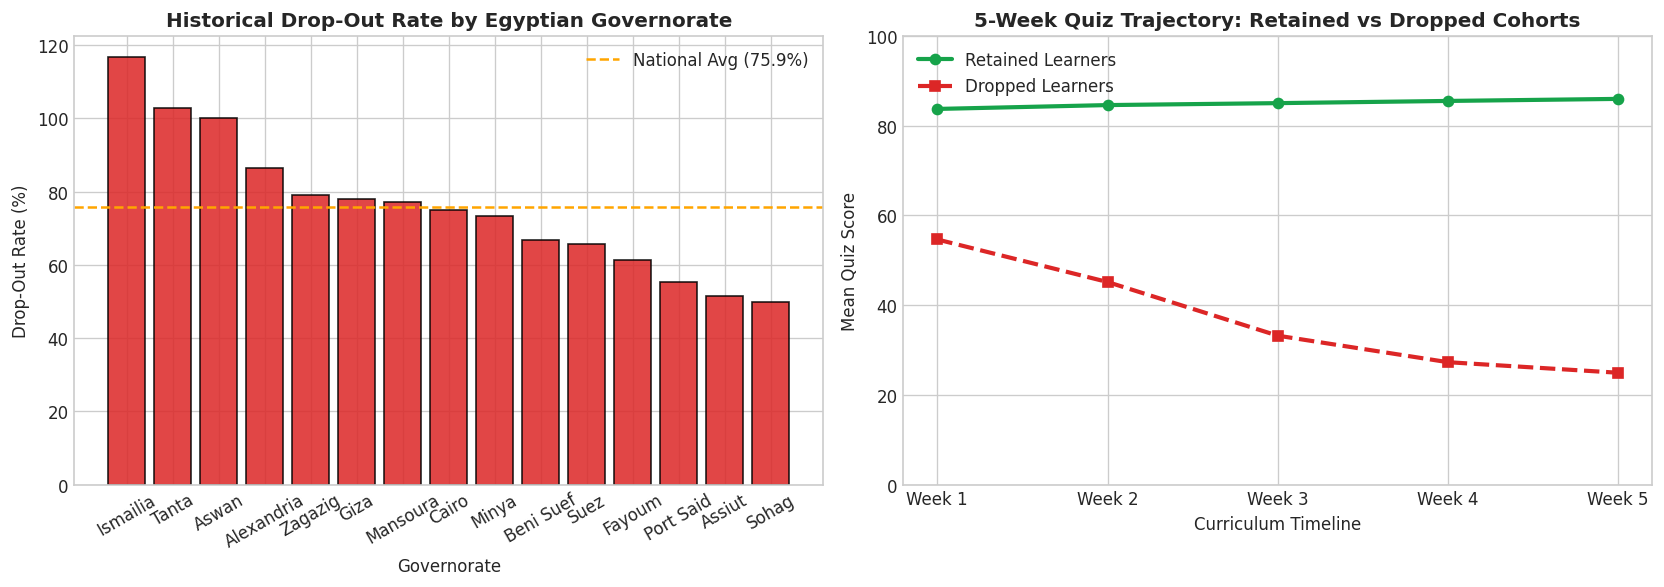

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Governorate Dropout Rates
cities = df_gov['governorate']
rates = df_gov['dropout_rate_pct']
colors = ['#dc2626' if r > 20.0 else '#2563eb' for r in rates]

axes[0].bar(cities, rates, color=colors, edgecolor='black', alpha=0.85)
axes[0].set_title('Historical Drop-Out Rate by Egyptian Governorate', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Drop-Out Rate (%)')
axes[0].set_xlabel('Governorate')
axes[0].tick_params(axis='x', rotation=30)
axes[0].axhline(y=np.mean(rates), color='orange', linestyle='--', label=f'National Avg ({np.mean(rates):.1f}%)')
axes[0].legend()

# 2. 5-Week Quiz Trajectory: Retained vs Dropped
retained = df_clean[df_clean['dropped_out'] == 0][quiz_cols].mean()
dropped = df_clean[df_clean['dropped_out'] == 1][quiz_cols].mean()
weeks = ['Week 1', 'Week 2', 'Week 3', 'Week 4', 'Week 5']

axes[1].plot(weeks, retained, marker='o', linewidth=2.5, color='#16a34a', label='Retained Learners')
axes[1].plot(weeks, dropped, marker='s', linewidth=2.5, color='#dc2626', linestyle='--', label='Dropped Learners')
axes[1].set_title('5-Week Quiz Trajectory: Retained vs Dropped Cohorts', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Mean Quiz Score')
axes[1].set_xlabel('Curriculum Timeline')
axes[1].set_ylim(0, 100)
axes[1].legend()

plt.tight_layout()
plt.show()

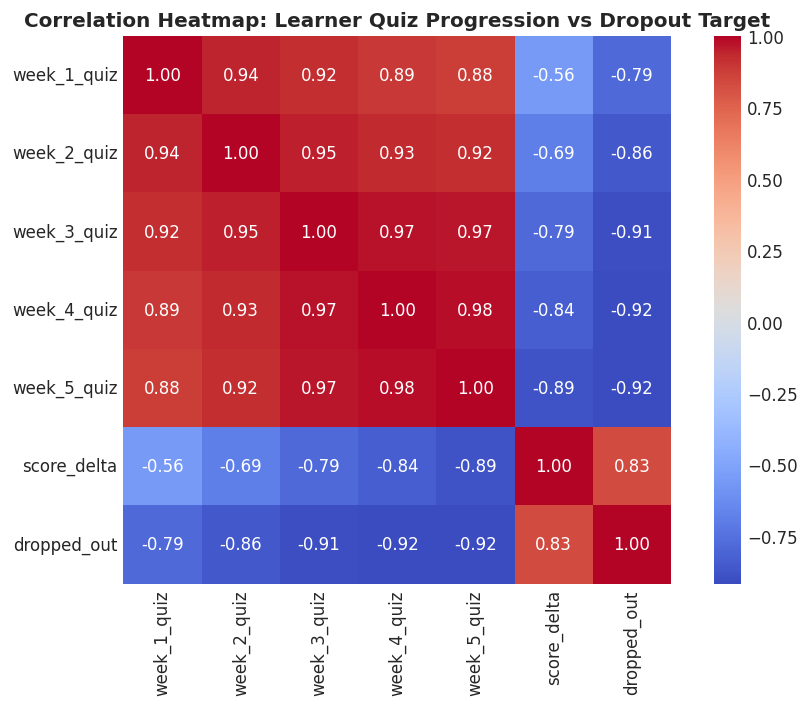

In [8]:
# Correlation Heatmap
df_clean['score_delta'] = df_clean['week_1_quiz'] - df_clean['week_5_quiz']
corr_cols = quiz_cols + ['score_delta', 'dropped_out']
corr = df_clean[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True)
plt.title('Correlation Heatmap: Learner Quiz Progression vs Dropout Target', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()